In [16]:
import numpy as np
import pandas as pd
import os
import pickle
import torch
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt
import scikitplot as skplt
from sklearn.metrics import roc_curve, auc

In [5]:
# 从文件中加载模型
with open('model_xgb_(NMRium).pkl', 'rb') as f:
    model_xgb_NMRium = pickle.load(f)

with open('model_xgb_(NMRium_NMRShiftDB).pkl', 'rb') as f:
    model_xgb_NMRium_NMRShiftDB = pickle.load(f)

In [43]:
df0 = pd.read_csv("./data/df_all_0813_processed.csv")
data_dict = torch.load("./data/df_all_0813_processed.pt", map_location=torch.device('cpu'))
valid_index = np.load('valid_index(NMRium).npy')
valid_index = valid_index.tolist()
valid_dict = {_:"" for _ in valid_index}
test_index = np.load('test_index(NMRium).npy')
test_index = test_index.tolist()
test_dict = {_:"" for _ in test_index}


data_test_list = []
y_test_list = []
data_valid_list = []
y_valid_list = []
for i in df0.index:
    if i in data_dict:
        if df0.loc[i, "source"] in ["NMRium", "NMRShiftDB"]:
            if i in test_dict:
                data_test_list.append(data_dict[i])
                y_test_list.extend([df0.loc[i, "label"]]*len(data_dict[i]))
            elif i in valid_dict:
                data_valid_list.append(data_dict[i])
                y_valid_list.extend([df0.loc[i, "label"]]*len(data_dict[i]))
        
X_test = torch.cat(data_test_list).numpy()
y_test = np.array(y_test_list)

X_valid = torch.cat(data_valid_list).numpy()
y_valid = np.array(y_valid_list)

print("X_test.shape", X_test.shape, "y_test.shape", y_test.shape)
print("X_val.shape", X_valid.shape, "y_val.shape", y_valid.shape)


X_test.shape (42664, 768) y_test.shape (42664,)
X_val.shape (42663, 768) y_val.shape (42663,)


In [28]:
data_dict_1 = torch.load("./data/positive_58_no_processed.pt", map_location=torch.device('cpu'))
X_test_1 = [v for k,v in data_dict_1.items()]
X_test_1 = torch.cat(X_test_1).numpy()
y_test_1 = np.ones(X_test_1.shape[0])

data_dict_2 = torch.load("./data/positive_58_processed.pt", map_location=torch.device('cpu'))
X_test_2 = [v for k,v in data_dict_2.items()]
X_test_2 = torch.cat(X_test_2).numpy()
y_test_2 = np.ones(X_test_2.shape[0])


In [60]:
y_pred_proba_1 = model_xgb_NMRium.predict_proba(X_test)
y_pred_proba_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_test)

y_valid_pred_proba_1 = model_xgb_NMRium.predict_proba(X_valid)
y_valid_pred_proba_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_valid)

y_test_pred_proba_1_1 = model_xgb_NMRium.predict_proba(X_test_1)
y_test_pred_proba_1_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_test_1)
y_test_pred_proba_2_1 = model_xgb_NMRium.predict_proba(X_test_2)
y_test_pred_proba_2_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_test_2)

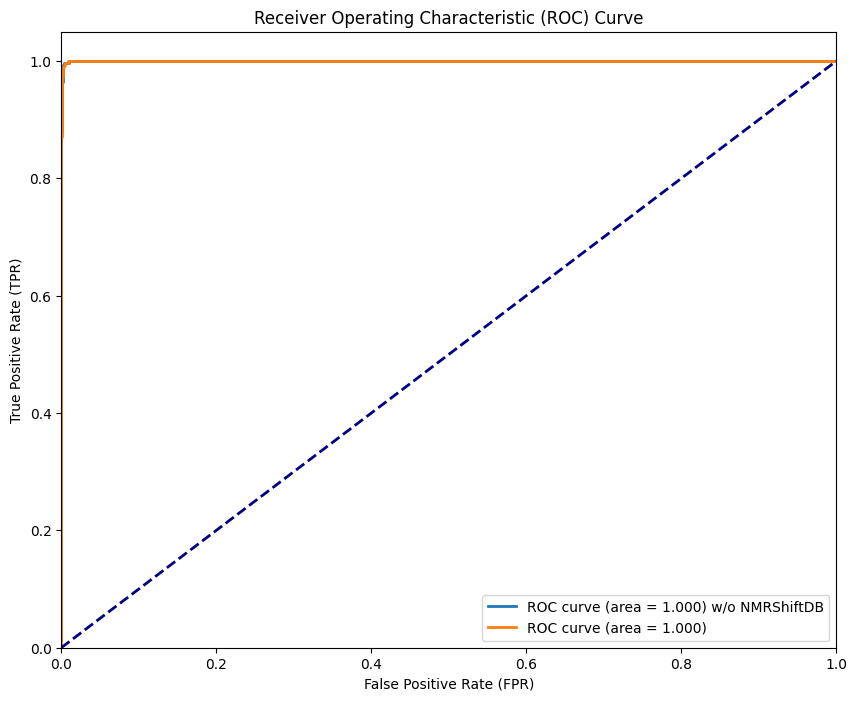

In [30]:
# Compute ROC curve and ROC area (AUC)
fpr1, tpr1, thresholds = roc_curve(y_test, y_pred_proba_1[:,1])
roc_auc1 = auc(fpr1, tpr1)

fpr2, tpr2, thresholds = roc_curve(y_test, y_pred_proba_2[:,1])
roc_auc2 = auc(fpr2, tpr2)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr1, tpr1, lw=2, label='ROC curve (area = %0.3f) w/o NMRShiftDB' % roc_auc1)
plt.plot(fpr2, tpr2, lw=2, label='ROC curve (area = %0.3f)' % roc_auc2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [ ]:
y_test_pred_proba_1_1 = model_xgb_NMRium.predict_proba(X_test_1)
y_test_pred_proba_1_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_test_1)
y_test_pred_proba_2_1 = model_xgb_NMRium.predict_proba(X_test_2)
y_test_pred_proba_2_2 = model_xgb_NMRium_NMRShiftDB.predict_proba(X_test_2)

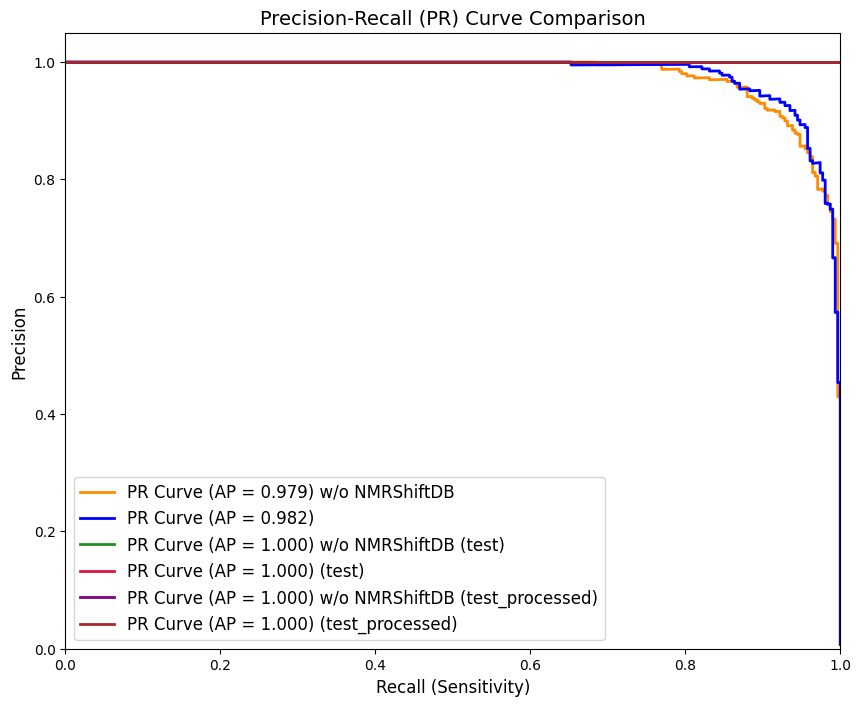

In [61]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# 计算 PRC 数据
precision1, recall1, _ = precision_recall_curve(y_test, y_pred_proba_1[:, 1])
average_precision1 = average_precision_score(y_test, y_pred_proba_1[:, 1])

precision2, recall2, _ = precision_recall_curve(y_test, y_pred_proba_2[:, 1])
average_precision2 = average_precision_score(y_test, y_pred_proba_2[:, 1])

precision3, recall3, _ = precision_recall_curve(y_test_1, y_test_pred_proba_1_1[:, 1])
average_precision3 = average_precision_score(y_test_1, y_test_pred_proba_1_1[:, 1])

precision4, recall4, _ = precision_recall_curve(y_test_1, y_test_pred_proba_1_2[:, 1])
average_precision4 = average_precision_score(y_test_1, y_test_pred_proba_1_1[:, 1])

precision5, recall5, _ = precision_recall_curve(y_test_2, y_test_pred_proba_2_1[:, 1])
average_precision5 = average_precision_score(y_test_2, y_test_pred_proba_2_1[:, 1])

precision6, recall6, _ = precision_recall_curve(y_test_2, y_test_pred_proba_2_2[:, 1])
average_precision6 = average_precision_score(y_test_2, y_test_pred_proba_2_2[:, 1])

# 绘制 PRC 曲线
plt.figure(figsize=(10, 8))
plt.plot(recall1, precision1, color='darkorange', lw=2,
        label=f'PR Curve (AP = {average_precision1:.3f}) w/o NMRShiftDB')
plt.plot(recall2, precision2, color='blue', lw=2,
        label=f'PR Curve (AP = {average_precision2:.3f})')
plt.plot(recall3, precision3, color='forestgreen', lw=2,
        label=f'PR Curve (AP = {average_precision3:.3f}) w/o NMRShiftDB (test)')
plt.plot(recall4, precision4, color='crimson', lw=2,
        label=f'PR Curve (AP = {average_precision4:.3f}) (test)')

# 新增第5条
plt.plot(recall5, precision5, color='purple', lw=2,
         label=f'PR Curve (AP = {average_precision5:.3f}) w/o NMRShiftDB (test_processed)')

# 新增第6条
plt.plot(recall6, precision6, color='brown', lw=2,
         label=f'PR Curve (AP = {average_precision6:.3f}) (test_processed)')

plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall (PR) Curve Comparison', fontsize=14)
plt.legend(loc="lower left", fontsize=12)
# plt.grid(True, alpha=0.3)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.show()

In [46]:
import numpy as np
from sklearn.metrics import roc_curve, confusion_matrix, precision_score, recall_score

def find_best_threshold_by_youden(y_true, y_pred_proba, pos_label=1):
    """
    使用约登指数（Youden's Index）从预测概率中找出最优的分类阈值。

    参数:
        y_true (array-like): 真实标签，值为 0 或 1
        y_pred_proba (array-like): 模型预测为正类的概率，shape (n_samples,)，即正类概率
        pos_label (int): 正类标签，默认是 1

    返回:
        dict: 包括最佳阈值 best_threshold，以及在该阈值下的
              fpr, tpr, thresholds, accuracy, precision, recall, specificity,
              以及 conf_matrix, tn, fp, fn, tp
    """
    y_pred_proba = np.asarray(y_pred_proba)
    if y_pred_proba.ndim != 1:
        raise ValueError("y_pred_proba 应该是 shape (n_samples,) 的正类概率数组")

    # -------------------------------
    # 1. 计算 ROC 曲线
    # -------------------------------
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba, pos_label=pos_label)

    # -------------------------------
    # 2. 计算 Youden's Index: J = TPR - FPR
    # -------------------------------
    youden_index = tpr - fpr

    # 找到最大约登指数对应的索引
    best_idx = np.argmax(youden_index)
    best_threshold = thresholds[best_idx]
    best_tpr = tpr[best_idx]
    best_fpr = fpr[best_idx]

    # -------------------------------
    # 3. 使用最佳阈值计算预测类别及各项指标
    # -------------------------------
    y_pred = (y_pred_proba >= best_threshold).astype(int)

    # 混淆矩阵
    conf_matrix = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = conf_matrix.ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    # -------------------------------
    # 4. 返回所有结果
    # -------------------------------
    results = {
        'best_threshold': best_threshold,
        'best_tpr': best_tpr,
        'best_fpr': best_fpr,
        'youden_index': best_tpr - best_fpr,
        'confusion_matrix': conf_matrix,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'tp': tp,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'specificity': specificity
    }

    return results

In [48]:
best_threshold_1 = find_best_threshold_by_youden(y_valid, y_valid_pred_proba_1[:, 1], pos_label=1)["best_threshold"]
best_threshold_2 = find_best_threshold_by_youden(y_valid, y_valid_pred_proba_2[:, 1], pos_label=1)["best_threshold"]

In [50]:
best_threshold_1, best_threshold_2

(0.0015040677, 0.035635494)

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
def calculate_metrics(y_true, y_pred_proba, threshold=0.5):
    """
    根据真实标签、模型输出的概率和阈值，计算准确率、精确率、召回率和混淆矩阵。

    参数:
        y_true (array-like): 真实标签，值为 0 或 1，shape (n_samples,)
        y_pred_proba (array-like): 模型预测的正类概率，通常为 shape (n_samples, 2)，取[:, 1]
                                   或者如果是 shape (n_samples,)，则假定已经是正类概率
        threshold (float): 判断为正类的概率阈值，默认为 0.5

    返回:
        dict: 包括 accuracy, precision, recall, confusion_matrix, tn, fp, fn, tp
    """

    # --------------------------
    # Step 1: 处理 y_pred_proba 输入，提取正类概率
    # --------------------------
    y_pred_proba = np.asarray(y_pred_proba)
    
    if y_pred_proba.ndim == 2:
        # 假定是 shape (n_samples, 2)，取第二列为正类概率
        y_pred_prob_positive = y_pred_proba[:, 1]
    elif y_pred_proba.ndim == 1:
        # 假定直接就是正类概率（例如某些模型直接输出 positive class 的概率）
        y_pred_prob_positive = y_pred_proba
    else:
        raise ValueError("y_pred_proba 必须是 shape (n_samples,) 或 (n_samples, 2) 的数组")

    # --------------------------
    # Step 2: 根据阈值生成预测类别 y_pred (0 或 1)
    # --------------------------
    y_pred = (y_pred_prob_positive >= threshold).astype(int)

    # --------------------------
    # Step 3: 计算指标
    # --------------------------
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)  # 正类为 1
    recall = recall_score(y_true, y_pred)       # 正类为 1
    conf_matrix = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = conf_matrix.ravel()

    # --------------------------
    # Step 4: 返回结果字典
    # --------------------------
    metrics = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'confusion_matrix': conf_matrix,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'tp': tp
    }

    return metrics

In [54]:
precision1, recall1, _ = precision_recall_curve(y_test, y_pred_proba_1[:, 1])
average_precision1 = average_precision_score(y_test, y_pred_proba_1[:, 1])

precision2, recall2, _ = precision_recall_curve(y_test, y_pred_proba_2[:, 1])
average_precision2 = average_precision_score(y_test, y_pred_proba_2[:, 1])

precision3, recall3, _ = precision_recall_curve(y_test_1, y_test_pred_proba_1[:, 1])
average_precision3 = average_precision_score(y_test_1, y_test_pred_proba_1[:, 1])

precision4, recall4, _ = precision_recall_curve(y_test_2, y_test_pred_proba_2[:, 1])
average_precision4 = average_precision_score(y_test_2, y_test_pred_proba_2[:, 1])

In [64]:
for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    print(threshold)
    print(calculate_metrics(y_test, y_pred_proba_1[:, 1], threshold))
    print()

for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    print(threshold)
    print(calculate_metrics(y_test_1, y_test_pred_proba_1_1[:, 1], threshold))
    print()

for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    print(threshold)
    print(calculate_metrics(y_test_2, y_test_pred_proba_2_1[:, 1], threshold))
    print()

0.0015040677
{'accuracy': 0.9944684042752672, 'precision': 0.566420664206642, 'recall': 0.9967532467532467, 'confusion_matrix': array([[42121,   235],
       [    1,   307]]), 'tn': 42121, 'fp': 235, 'fn': 1, 'tp': 307}

0.01
{'accuracy': 0.996812300768798, 'precision': 0.6954545454545454, 'recall': 0.9935064935064936, 'confusion_matrix': array([[42222,   134],
       [    2,   306]]), 'tn': 42222, 'fp': 134, 'fn': 2, 'tp': 306}

0.05
{'accuracy': 0.997867054190887, 'precision': 0.7803617571059431, 'recall': 0.9805194805194806, 'confusion_matrix': array([[42271,    85],
       [    6,   302]]), 'tn': 42271, 'fp': 85, 'fn': 6, 'tp': 302}

0.1
{'accuracy': 0.9981951996999813, 'precision': 0.8181818181818182, 'recall': 0.9642857142857143, 'confusion_matrix': array([[42290,    66],
       [   11,   297]]), 'tn': 42290, 'fp': 66, 'fn': 11, 'tp': 297}

0.3
{'accuracy': 0.998710856928558, 'precision': 0.8940809968847352, 'recall': 0.9318181818181818, 'confusion_matrix': array([[42322,    34],

In [65]:
# 准备存储所有结果的列表
results = []

# ===== 第一组数据：y_test, y_pred_proba_1[:,1] =====
y_true = y_test
y_pred_proba = y_pred_proba_1[:, 1]
dataset_name = 'dataset1'

for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test, y_pred_proba_1[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
        # 如果你有 AP，也可以这样添加（如果 calculate_metrics 返回了它）
        # 'average_precision': metrics.get('average_precision', None)
    }
    results.append(row)

# ===== 第二组数据：y_test_1, y_test_pred_proba_1_1[:,1] =====
y_true = y_test_1
y_pred_proba = y_test_pred_proba_1_1[:, 1]
dataset_name = 'dataset2'

for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test_1, y_test_pred_proba_1_1[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
    }
    results.append(row)

# ===== 第三组数据：y_test_2, y_test_pred_proba_2_1[:,1] =====
y_true = y_test_2
y_pred_proba = y_test_pred_proba_2_1[:, 1]
dataset_name = 'dataset3'

for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test_2, y_test_pred_proba_2_1[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
    }
    results.append(row)

# ===== 构建 DataFrame =====
df_results = pd.DataFrame(results)

# ===== 查看结果 =====
print(df_results)

     dataset  threshold  accuracy  precision    recall     tn   fp  fn   tp
0   dataset1   0.001504  0.994468   0.566421  0.996753  42121  235   1  307
1   dataset1   0.010000  0.996812   0.695455  0.993506  42222  134   2  306
2   dataset1   0.050000  0.997867   0.780362  0.980519  42271   85   6  302
3   dataset1   0.100000  0.998195   0.818182  0.964286  42290   66  11  297
4   dataset1   0.300000  0.998711   0.894081  0.931818  42322   34  21  287
5   dataset1   0.500000  0.998758   0.920792  0.905844  42332   24  29  279
6   dataset2   0.001504  0.810345   1.000000  0.810345      0    0  11   47
7   dataset2   0.010000  0.775862   1.000000  0.775862      0    0  13   45
8   dataset2   0.050000  0.758621   1.000000  0.758621      0    0  14   44
9   dataset2   0.100000  0.706897   1.000000  0.706897      0    0  17   41
10  dataset2   0.300000  0.620690   1.000000  0.620690      0    0  22   36
11  dataset2   0.500000  0.568966   1.000000  0.568966      0    0  25   33
12  dataset3

In [66]:
df_results.to_csv("temp_result.csv")

In [69]:
# 准备存储所有结果的列表
results = []

# ===== 第一组数据：y_test, y_pred_proba_1[:,1] =====
y_true = y_test
y_pred_proba = y_pred_proba_1[:, 1]
dataset_name = 'dataset1'

for threshold in [best_threshold_2, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test, y_pred_proba_2[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
        # 如果你有 AP，也可以这样添加（如果 calculate_metrics 返回了它）
        # 'average_precision': metrics.get('average_precision', None)
    }
    results.append(row)

# ===== 第二组数据：y_test_1, y_test_pred_proba_1_1[:,1] =====
y_true = y_test_2
y_pred_proba = y_test_pred_proba_1_2[:, 1]
dataset_name = 'dataset2'

for threshold in [best_threshold_2, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test_1, y_test_pred_proba_1_2[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
    }
    results.append(row)

# ===== 第三组数据：y_test_2, y_test_pred_proba_2_1[:,1] =====
y_true = y_test_2
y_pred_proba = y_test_pred_proba_2_1[:, 1]
dataset_name = 'dataset3'

for threshold in [best_threshold_2, 0.01, 0.05, 0.1, 0.3, 0.5]:
    metrics = calculate_metrics(y_test_2, y_test_pred_proba_2_2[:,1], threshold)
    row = {
        'dataset': dataset_name,
        'threshold': threshold,
        'accuracy': metrics['accuracy'],
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'tn': metrics['tn'],
        'fp': metrics['fp'],
        'fn': metrics['fn'],
        'tp': metrics['tp'],
    }
    results.append(row)

# ===== 构建 DataFrame =====
df_results = pd.DataFrame(results)

# ===== 查看结果 =====
print(df_results)

     dataset  threshold  accuracy  precision    recall     tn   fp  fn   tp
0   dataset1   0.035635  0.998101   0.802667  0.977273  42282   74   7  301
1   dataset1   0.010000  0.997094   0.715962  0.990260  42235  121   3  305
2   dataset1   0.050000  0.998312   0.824176  0.974026  42292   64   8  300
3   dataset1   0.100000  0.998594   0.862573  0.957792  42309   47  13  295
4   dataset1   0.300000  0.998851   0.900929  0.944805  42324   32  17  291
5   dataset1   0.500000  0.998992   0.931596  0.928571  42335   21  22  286
6   dataset2   0.035635  0.724138   1.000000  0.724138      0    0  16   42
7   dataset2   0.010000  0.793103   1.000000  0.793103      0    0  12   46
8   dataset2   0.050000  0.724138   1.000000  0.724138      0    0  16   42
9   dataset2   0.100000  0.672414   1.000000  0.672414      0    0  19   39
10  dataset2   0.300000  0.637931   1.000000  0.637931      0    0  21   37
11  dataset2   0.500000  0.603448   1.000000  0.603448      0    0  23   35
12  dataset3

In [70]:
df_results.to_csv("temp_result_2.csv")

In [57]:
for threshold in [best_threshold_1, 0.01, 0.05, 0.1, 0.3, 0.5]:
    print(threshold)
    print(calculate_metrics(y_test_1, y_test_pred_proba_1[:, 1], threshold))
    print()


0.0015040677
{'accuracy': 0.8103448275862069, 'precision': 1.0, 'recall': 0.8103448275862069, 'confusion_matrix': array([[ 0,  0],
       [11, 47]]), 'tn': 0, 'fp': 0, 'fn': 11, 'tp': 47}

0.01
{'accuracy': 0.7758620689655172, 'precision': 1.0, 'recall': 0.7758620689655172, 'confusion_matrix': array([[ 0,  0],
       [13, 45]]), 'tn': 0, 'fp': 0, 'fn': 13, 'tp': 45}

0.05
{'accuracy': 0.7586206896551724, 'precision': 1.0, 'recall': 0.7586206896551724, 'confusion_matrix': array([[ 0,  0],
       [14, 44]]), 'tn': 0, 'fp': 0, 'fn': 14, 'tp': 44}

0.1
{'accuracy': 0.7068965517241379, 'precision': 1.0, 'recall': 0.7068965517241379, 'confusion_matrix': array([[ 0,  0],
       [17, 41]]), 'tn': 0, 'fp': 0, 'fn': 17, 'tp': 41}

0.3
{'accuracy': 0.6206896551724138, 'precision': 1.0, 'recall': 0.6206896551724138, 'confusion_matrix': array([[ 0,  0],
       [22, 36]]), 'tn': 0, 'fp': 0, 'fn': 22, 'tp': 36}

0.5
{'accuracy': 0.5689655172413793, 'precision': 1.0, 'recall': 0.5689655172413793, 'con

In [58]:
for threshold in [best_threshold_2, 0.01, 0.05, 0.1, 0.3, 0.5]:
    print(threshold)
    print(calculate_metrics(y_test_2, y_test_pred_proba_2[:, 1], threshold))
    print()

0.035635494
{'accuracy': 0.7586206896551724, 'precision': 1.0, 'recall': 0.7586206896551724, 'confusion_matrix': array([[ 0,  0],
       [14, 44]]), 'tn': 0, 'fp': 0, 'fn': 14, 'tp': 44}

0.01
{'accuracy': 0.8103448275862069, 'precision': 1.0, 'recall': 0.8103448275862069, 'confusion_matrix': array([[ 0,  0],
       [11, 47]]), 'tn': 0, 'fp': 0, 'fn': 11, 'tp': 47}

0.05
{'accuracy': 0.7586206896551724, 'precision': 1.0, 'recall': 0.7586206896551724, 'confusion_matrix': array([[ 0,  0],
       [14, 44]]), 'tn': 0, 'fp': 0, 'fn': 14, 'tp': 44}

0.1
{'accuracy': 0.7241379310344828, 'precision': 1.0, 'recall': 0.7241379310344828, 'confusion_matrix': array([[ 0,  0],
       [16, 42]]), 'tn': 0, 'fp': 0, 'fn': 16, 'tp': 42}

0.3
{'accuracy': 0.6724137931034483, 'precision': 1.0, 'recall': 0.6724137931034483, 'confusion_matrix': array([[ 0,  0],
       [19, 39]]), 'tn': 0, 'fp': 0, 'fn': 19, 'tp': 39}

0.5
{'accuracy': 0.6551724137931034, 'precision': 1.0, 'recall': 0.6551724137931034, 'conf